In [1]:
import osmnx as ox 
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
import numpy as np
from geopy.distance import geodesic
import geopandas as gpd

In [5]:
#Specifying the place name 
place_name = "Ahmedabad District, Gujarat, India"

In [6]:
#Creating a file to store all outputs
f1 = open("ahemdabad_osmnx.txt","w")

In [7]:
#Fetch OSM from the location
graph_city = ox.graph_from_place(place_name, network_type="all")

In [8]:
# Relabel nodes starting from 0
graph_city = nx.relabel.convert_node_labels_to_integers(graph_city, first_label=0, ordering="sorted")


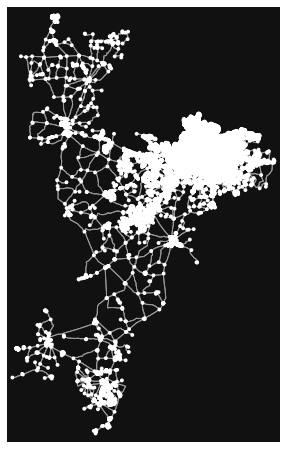

In [9]:
#Plot the Streets 
fig, ax = ox.plot_graph(graph_city,save=True,filepath='ahmedabad_osmnxplot.png')

In [10]:
#Calculating the nodes and edges for the selected area
nodes_city, edges_city = ox.graph_to_gdfs(graph_city)

In [11]:
#Printind the matrix size of nodes and edges
nodes = print("Size of node matrix for the entire city",nodes_city.shape)
edges = print("Size of edge matrix for the entire city",edges_city.shape)

#Writing outputs in the file
f1.write("Size of node matrix(MultiDiGraph) for the entire city: " + str(nodes_city.shape) + "\n")
f1.write("Size of edge matrix(MultiDiGraph) for the entire city: " + str(edges_city.shape) + "\n")

Size of node matrix for the entire city (59650, 6)
Size of edge matrix for the entire city (148866, 16)


68

In [12]:
#Calculating the area
area = ox.geocode_to_gdf(place_name)
print(area)

#Saving output in a file
f1.write("Details of area of the city is:"+ str(area) + "\n")

                                            geometry  bbox_north  bbox_south  \
0  POLYGON ((71.83641 22.26119, 71.84285 22.25929...   23.509048   21.946148   

   bbox_east  bbox_west   place_id  osm_type   osm_id        lat        lon  \
0   72.84115  71.836411  214132808  relation  1953566  22.728054  72.300544   

      class            type  place_rank  importance     addresstype  \
0  boundary  administrative          10    0.460408  state_district   

                 name                        display_name  
0  Ahmedabad District  Ahmedabad District, Gujarat, India  


614

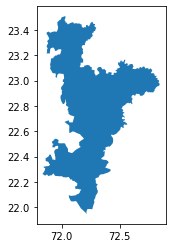

In [13]:
# Plotting the area of the city
ax = area.plot()

# Save the plot to a file (e.g., as a PNG image)
ax.figure.savefig('ahemdabad_area.png', bbox_inches='tight')


In [14]:
#Calculating the basic_stats
basic_stats = ox.basic_stats(graph_city)

In [15]:
#Printing basic stats by using OSMnx
print("Basic Stats calculated using OSMnx for the entire city:",basic_stats)

#Saving output in a file
f1.write("Basic Stats calculated using OSMnx for the entire city: "+ str(basic_stats) + "\n")

Basic Stats calculated using OSMnx for the entire city: {'n': 59650, 'm': 148866, 'k_avg': 4.991316010058676, 'edge_length_total': 19547134.36500004, 'edge_length_avg': 131.3069093345696, 'streets_per_node_avg': 2.683235540653814, 'streets_per_node_counts': {0: 0, 1: 13594, 2: 110, 3: 37672, 4: 8158, 5: 105, 6: 10, 7: 0, 8: 1}, 'streets_per_node_proportions': {0: 0.0, 1: 0.22789606035205365, 2: 0.0018440905280804694, 3: 0.6315507124895222, 4: 0.13676445934618608, 5: 0.001760268231349539, 6: 0.00016764459346186087, 7: 0.0, 8: 1.6764459346186085e-05}, 'intersection_count': 46056, 'street_length_total': 10626297.751999905, 'street_segment_count': 79895, 'street_length_avg': 133.00328871643913, 'circuity_avg': 1.0553568846496963, 'self_loop_proportion': 0.0013517742036422806}


783

In [16]:
#Create a network
G_nk = nx.MultiDiGraph()

#Adding nodes and edges using OSM data
for u,v,data in graph_city.edges(data=True):
    #Coordinates for each points using networkx
    u_lat,u_lon = graph_city.nodes[u]['y'], graph_city.nodes[u]['x']
    v_lat,v_lon = graph_city.nodes[v]['y'], graph_city.nodes[v]['x']

    #Calculating the geodesic distance between the connected points
    distance = geodesic((u_lat,u_lon),(v_lat,v_lon)).kilometers
   
    #Adding nodes,edges and weights=distance between connected points
    G_nk.add_node(u, x = graph_city.nodes[u]['x'], y = graph_city.nodes[u]['y'])
    G_nk.add_node(v, x = graph_city.nodes[v]['x'], y = graph_city.nodes[v]['y'])
    G_nk.add_edge(u,v, weight = distance)
    

In [17]:
#Checking number of nodes and edges
num_nodes = print("Number of nodes for MultiDiGraph = ",G_nk.number_of_nodes())
num_edges = print("Number of edges for MultiDiGraph = ",G_nk.number_of_edges())


Number of nodes for MultiDiGraph =  59650
Number of edges for MultiDiGraph =  148866


In [18]:
# Converting MultiDiGraph into an undirected network 
G = nx.Graph(G_nk)

In [19]:
#Removing the self loops
G.remove_edges_from([(u, v) for u, v in G.edges() if u == v])

In [20]:
#Checking number of nodes and edges
num_nodes = print("Number of nodes for UndirectedGraph without selfloops = ",G.number_of_nodes())
num_edges = print("Number of edges for UndirectedGraph without selfloops = ",G.number_of_edges())

#Saving output in a file
f1.write("Number of nodes for UndirectedGraph without selfloops = "+ str(G.number_of_nodes()) + "\n")
f1.write("Number of edges for UndirectedGraph without selfloops = "+ str(G.number_of_edges()) + "\n")

Number of nodes for UndirectedGraph without selfloops =  59650
Number of edges for UndirectedGraph without selfloops =  79214


62

In [21]:
#Closing the outputfile
f1.close()

In [22]:
# Downloading the graphml file for the networkx data
nx.write_graphml(G, "ahemdabad_street_network.graphml")
